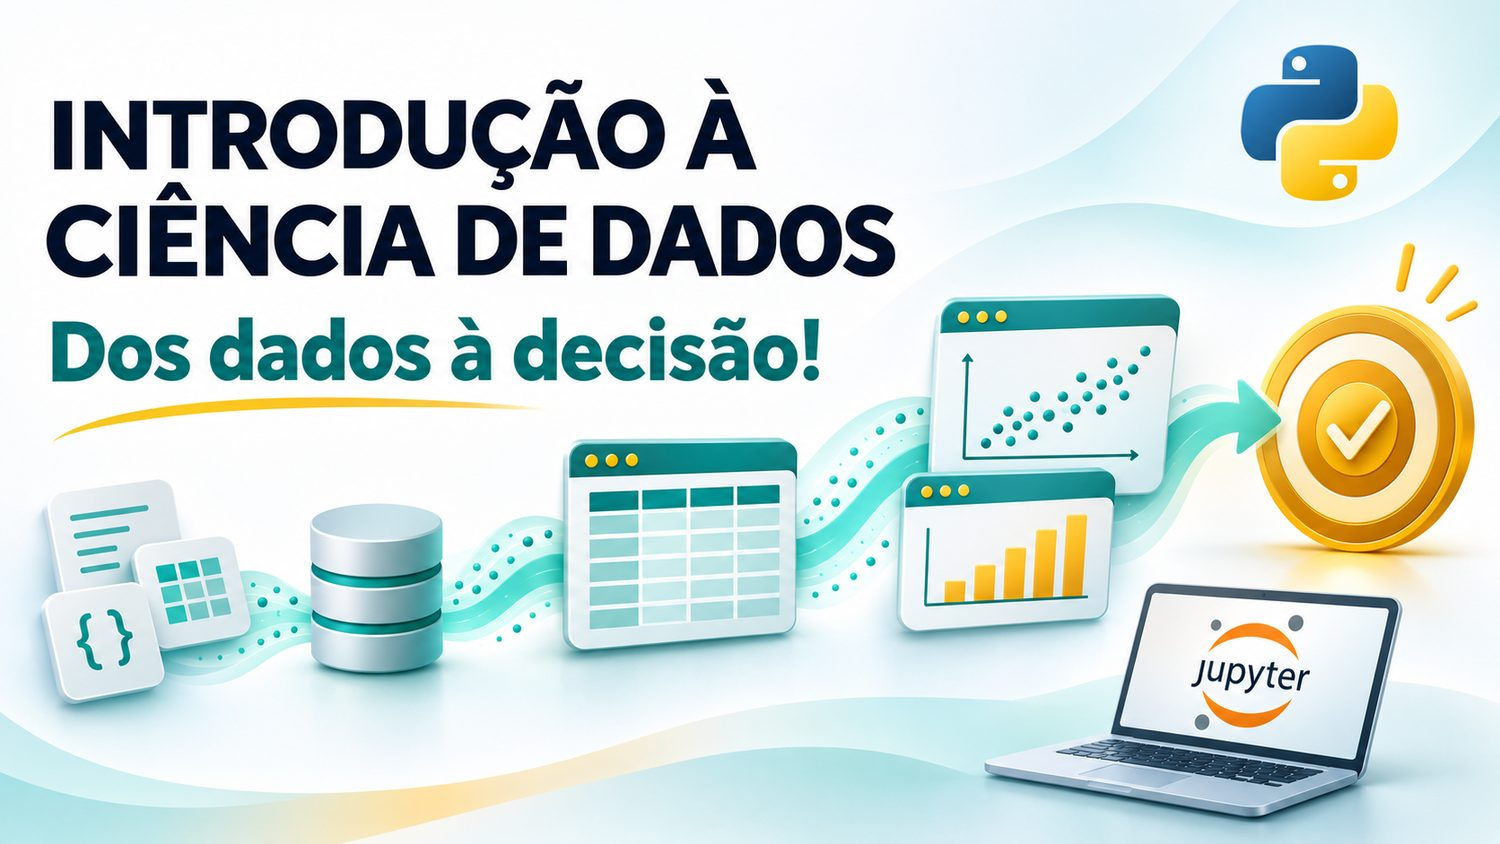

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_2_fontes_tipos_estruturas/04_Qualidade_dos_Dados.ipynb)

# Capítulo 4 – Qualidade dos dados

Dados bem organizados podem estar errados. Neste capítulo recebemos um ficheiro de vendas com os problemas que aparecem em qualquer projeto real, fazemos-lhe uma auditoria passo a passo e reparamos o que tem reparação, registando cada decisão. No fim comparamos as conclusões que se tirariam antes e depois.

> **Objetivos:** reconhecer problemas de consistência, completude, validade, duplicação e enviesamento; fazer uma auditoria sistemática a uma tabela; reparar com base em evidência, sem inventar valores; documentar as alterações e a incerteza que fica por resolver.

**Pré-requisitos:** capítulos 1 a 3 deste módulo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_padaria(semente=7):
    """Gera os dados de uma cadeia fictícia de padarias (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    lojas = pd.DataFrame({
        "loja_id": ["0041", "0042", "0043", "0107", "0212", "0305"],
        "zona": ["Baixa", "Baixa", "Ribeira", "Estação", "Universidade", "Mercado"],
        "producao_habitual": [320, 260, 180, 400, 220, 300]})
    dias = pd.date_range("2026-03-02", periods=84, freq="D")          # doze semanas, de segunda a domingo
    chuva = np.where(rng.random(84) < 0.35, rng.gamma(2.0, 3.0, 84).round(1), 0.0)
    meteo = pd.DataFrame({"data": dias, "chuva_mm": chuva})
    eventos = pd.DataFrame({
        "data": pd.to_datetime(["2026-03-14", "2026-03-28", "2026-04-11", "2026-04-25", "2026-05-09", "2026-05-16"]),
        "zona": ["Ribeira", "Mercado", "Baixa", "Baixa", "Ribeira", "Universidade"],
        "evento": ["Feira do livro", "Mercado de produtores", "Maratona", "Desfile", "Festival de rua", "Dia aberto"]})
    fator_dia = [0.95, 0.90, 0.92, 0.97, 1.06, 1.20, 1.08]            # segunda a domingo
    linhas = []
    for loja in lojas.itertuples():
        for dia, mm in zip(dias, chuva):
            ha_evento = ((eventos["data"] == dia) & (eventos["zona"] == loja.zona)).any()
            procura = (loja.producao_habitual * 0.9 * fator_dia[dia.dayofweek] * (1 - 0.012 * mm)
                       * (1.35 if ha_evento else 1.0) * rng.normal(1.0, 0.07))
            linhas.append((loja.loja_id, dia, loja.producao_habitual, int(min(round(procura), loja.producao_habitual))))
    vendas = pd.DataFrame(linhas, columns=["loja_id", "data", "produzidos", "vendidos"])
    return lojas, vendas, meteo, eventos


lojas, vendas, meteo, eventos = gerar_padaria()
vendas.head()

,loja_id,data,produzidos,vendidos
0,0041,2026-03-02,320,260
1,0041,2026-03-03,320,250
2,0041,2026-03-04,320,290
3,0041,2026-03-05,320,253
4,0041,2026-03-06,320,253


## Cinco famílias de problemas

| Família | O que é | Exemplos |
| --- | --- | --- |
| **Consistência** | A mesma coisa escrita de formas diferentes | Unidades misturadas, identificadores com e sem zeros, datas em convenções diferentes |
| **Completude** | Falta informação | Campos vazios; dias ou lojas que não aparecem |
| **Validade** | Valores que violam as regras do esquema | Vendas negativas; vender mais do que se recebeu |
| **Duplicação** | A mesma observação aparece mais de uma vez | Um ficheiro enviado duas vezes |
| **Enviesamento** | Distorção sistemática causada pela forma de recolha, de amostragem ou de medição | Uma loja que só comunica os dias de semana |

As quatro primeiras encontram-se olhando para a tabela. A quinta é a mais perigosa, porque os dados enviesados têm bom aspeto: estão completos, válidos e consistentes, e contam uma história errada.

## Um ficheiro como os que chegam na prática

A função seguinte pega nas vendas limpas e introduz-lhes problemas. Num projeto real não terias a versão limpa: aqui serve para, no fim, medirmos quanto a reparação recuperou.

In [3]:
def estragar(vendas, semente=3):
    """Devolve uma cópia das vendas com problemas de qualidade, como chegaria de seis lojas diferentes."""
    rng = np.random.default_rng(semente)
    b = vendas.copy()
    b["vendidos"] = b["vendidos"].astype(float)
    em_duzias = (b["loja_id"] == "0107") & (b["data"] >= "2026-04-13")
    b.loc[em_duzias, "vendidos"] = (b.loc[em_duzias, "vendidos"] / 12).round()
    avaria = (b["loja_id"] == "0043") & b["data"].between("2026-04-06", "2026-04-12")
    b.loc[avaria, "vendidos"] = np.nan
    b.loc[b[b["loja_id"] == "0305"].sample(3, random_state=1).index, "vendidos"] *= 10
    b.loc[b[b["loja_id"] == "0042"].sample(2, random_state=2).index, "vendidos"] = -1
    b = b[~((b["loja_id"] == "0212") & (b["data"].dt.dayofweek >= 5))]
    reenvio = b[(b["loja_id"] == "0042") & b["data"].between("2026-05-04", "2026-05-10")]
    b = pd.concat([b, reenvio], ignore_index=True)
    b["data"] = np.where(b["loja_id"] == "0305", b["data"].dt.strftime("%d/%m/%Y"), b["data"].dt.strftime("%Y-%m-%d"))
    sem_zeros = (b["loja_id"] == "0041") & (rng.random(len(b)) < 0.4)
    b.loc[sem_zeros, "loja_id"] = "41"
    return b.sample(frac=1, random_state=0).reset_index(drop=True)


bruto = estragar(vendas)       # os dados tal como chegaram: nunca se alteram
bruto.head(8)

,loja_id,data,produzidos,vendidos
0,0041,2026-03-17,320,268.0
1,0043,2026-05-23,180,180.0
2,0042,2026-04-29,260,196.0
3,0212,2026-03-27,220,215.0
4,0042,2026-03-08,260,234.0
5,0305,24/03/2026,300,216.0
6,0042,2026-05-01,260,260.0
7,0212,2026-03-17,220,185.0


> **Primeira regra: os dados em bruto não se alteram.** Todas as correções fazem-se numa cópia, com código. Assim é sempre possível voltar atrás, refazer e mostrar a outra pessoa o que foi feito.

## Auditoria

### Primeiro olhar

In [4]:
print("Linhas:", len(bruto), "| esperadas:", 6 * 84, "(6 lojas × 84 dias)\n")
print(bruto.dtypes, "\n")
print(bruto.describe().round(1))

Linhas: 487 | esperadas: 504 (6 lojas × 84 dias)

loja_id           str
data              str
produzidos      int64
vendidos      float64
dtype: object 

       produzidos  vendidos
count       487.0     480.0
mean        282.7     232.0
std          71.2     192.9
min         180.0      -1.0
25%         220.0     178.0
50%         300.0     231.0
75%         320.0     275.2
max         400.0    2660.0


Só este resumo já levanta quatro suspeitas:

- o número de linhas não é o esperado;
- `data` é texto;
- o mínimo de `vendidos` é negativo;
- o máximo de `vendidos` é muito superior ao máximo de `produzidos`.

### Consistência: identificadores, datas e unidades

In [5]:
print("Identificadores:\n", bruto["loja_id"].value_counts().sort_index(), "\n")

formato = np.select([bruto["data"].str.fullmatch(r"\d{4}-\d{2}-\d{2}"), bruto["data"].str.fullmatch(r"\d{2}/\d{2}/\d{4}")],
                    ["AAAA-MM-DD", "DD/MM/AAAA"], "outro")
print("Formatos de data por loja:\n", pd.crosstab(bruto["loja_id"], formato))

Identificadores:
 loja_id
0041    50
0042    91
0043    84
0107    84
0212    60
0305    84
41      34
Name: count, dtype: int64 

Formatos de data por loja:
 col_0    AAAA-MM-DD  DD/MM/AAAA
loja_id                        
0041             50           0
0042             91           0
0043             84           0
0107             84           0
0212             60           0
0305              0          84
41               34           0


Há **sete** identificadores para seis lojas: `41` não existe no cadastro, e `0041` tem menos linhas do que as outras lojas. E a loja `0305` escreve as datas noutro formato.

Para as unidades, comparamos a fração da produção que cada loja diz ter vendido, ao longo do tempo.

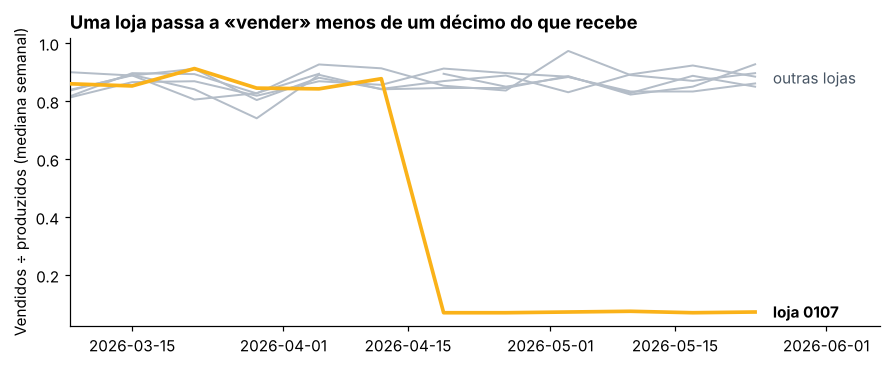

Loja 0107: razão entre o depois e o antes = 0.084   (1/12 = 0.083)


In [6]:
def ler_datas(coluna):
    """Converte datas escritas em AAAA-MM-DD ou em DD/MM/AAAA."""
    com_barras = coluna.str.contains("/")
    datas = pd.to_datetime(coluna.where(~com_barras), format="%Y-%m-%d")
    return datas.fillna(pd.to_datetime(coluna.where(com_barras), format="%d/%m/%Y"))


auditoria = bruto.copy()
auditoria["loja_id"] = auditoria["loja_id"].str.zfill(4)
auditoria["data"] = ler_datas(auditoria["data"])
auditoria["fracao"] = auditoria["vendidos"] / auditoria["produzidos"]
semanal = auditoria.groupby(["loja_id", pd.Grouper(key="data", freq="W")])["fracao"].median().unstack(0)

fig, ax = plt.subplots(figsize=(9.5, 3.4))
for loja in semanal.columns:
    destaque = loja == "0107"
    ax.plot(semanal.index, semanal[loja], color=AVISO if destaque else CINZA, lw=2.4 if destaque else 1.3, zorder=3 if destaque else 2)
ax.text(semanal.index[-1] + pd.Timedelta(days=2), semanal["0107"].iloc[-1], "loja 0107", va="center", fontweight="bold")
ax.text(semanal.index[-1] + pd.Timedelta(days=2), 0.88, "outras lojas", va="center", color="#465463")
ax.set_xlim(semanal.index[0], semanal.index[-1] + pd.Timedelta(days=14))
ax.set_ylabel("Vendidos ÷ produzidos (mediana semanal)")
ax.set_title("Uma loja passa a «vender» menos de um décimo do que recebe")
plt.show()

depois = auditoria[(auditoria["loja_id"] == "0107") & (auditoria["data"] >= "2026-04-13")]["fracao"].median()
antes = auditoria[(auditoria["loja_id"] == "0107") & (auditoria["data"] < "2026-04-13")]["fracao"].median()
print(f"Loja 0107: razão entre o depois e o antes = {depois / antes:.3f}   (1/12 = {1 / 12:.3f})")

A queda da loja `0107` acontece de um dia para o outro e a razão entre o depois e o antes é quase exatamente 1/12. A hipótese de os valores terem passado a vir em dúzias é muito forte, mas continua a ser uma **hipótese**: confirma-se com a loja.

### Completude, validade e duplicação num só mapa

A figura seguinte mostra o estado de cada combinação de loja e dia.

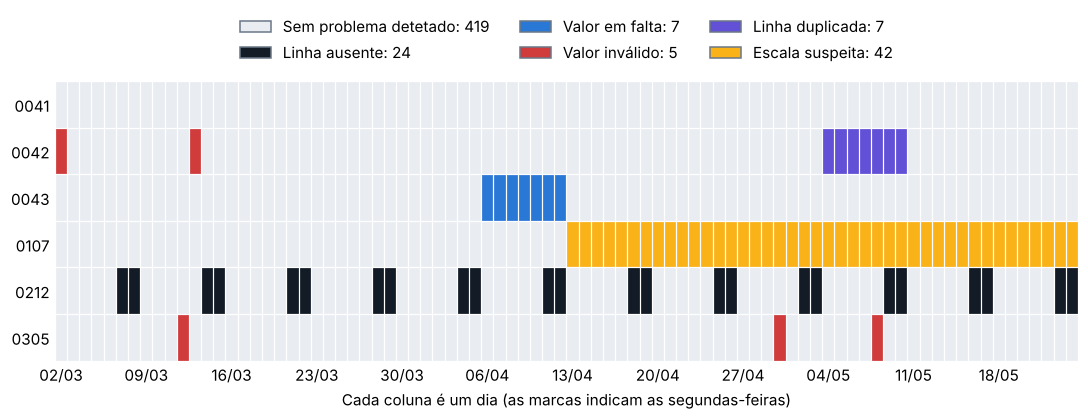

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

dias = pd.date_range("2026-03-02", periods=84, freq="D")
ids = list(lojas["loja_id"])
estado = pd.DataFrame(0, index=ids, columns=dias)                       # 0 = sem problema detetado
contagem = auditoria.groupby(["loja_id", "data"]).size().unstack(fill_value=0).reindex(index=ids, columns=dias, fill_value=0)
primeiro = auditoria.drop_duplicates(["loja_id", "data"]).set_index(["loja_id", "data"])
vendidos = primeiro["vendidos"].unstack().reindex(index=ids, columns=dias)
produzidos = primeiro["produzidos"].unstack().reindex(index=ids, columns=dias)

estado[(vendidos / produzidos) < 0.2] = 5                               # escala suspeita
estado[(vendidos < 0) | (vendidos > produzidos)] = 3                    # valor inválido
estado[vendidos.isna() & (contagem > 0)] = 2                            # valor em falta
estado[contagem > 1] = 4                                                # linha duplicada
estado[contagem == 0] = 1                                               # linha ausente

legenda = ["Sem problema detetado", "Linha ausente", "Valor em falta", "Valor inválido", "Linha duplicada", "Escala suspeita"]
cores = ["#e9edf1", TINTA, AZUL, MAU, VIOLETA, AVISO]
fig, ax = plt.subplots(figsize=(12, 3.3))
ax.imshow(estado.values, cmap=ListedColormap(cores), vmin=0, vmax=5, aspect="auto", interpolation="nearest")
ax.set_yticks(range(6), ids)
ax.set_xticks(range(0, 84, 7), [d.strftime("%d/%m") for d in dias[::7]])
ax.set_xticks(np.arange(-0.5, 84, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 6, 1), minor=True)
ax.grid(which="minor", color="white", lw=0.8)
ax.tick_params(which="both", length=0)
ax.spines[:].set_visible(False)
ax.set_xlabel("Cada coluna é um dia (as marcas indicam as segundas-feiras)")
ax.legend(handles=[Patch(fc=c, ec="#6b7887", label=f"{t}: {int((estado.values == i).sum())}") for i, (t, c) in enumerate(zip(legenda, cores))],
          ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02))
plt.show()

O mapa mostra de uma vez o que as tabelas-resumo escondem:

- **loja `0043`:** uma semana inteira de valores em falta (azul). Um bloco contínuo aponta para uma avaria, e não para esquecimentos ao acaso.
- **loja `0042`:** uma semana de linhas duplicadas (violeta) e dois valores inválidos (vermelho).
- **loja `0305`:** três valores inválidos, espalhados.
- **loja `0107`:** escala suspeita a partir de 13 de abril (amarelo).
- **loja `0212`:** faltam linhas com um padrão regular (escuro): dois dias em cada sete.

O último caso merece um olhar mais atento.

### Enviesamento: o que falta segue um padrão

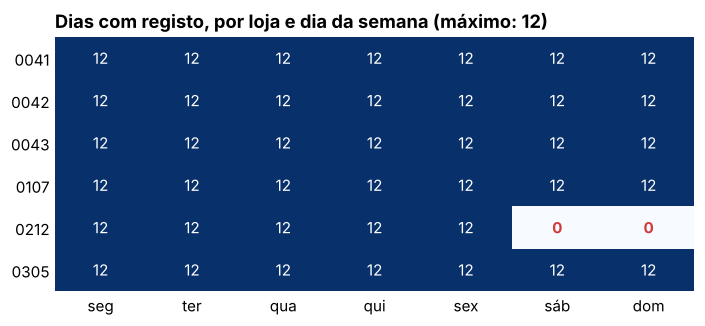

In [8]:
nomes = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
cobertura = (auditoria.drop_duplicates(["loja_id", "data"]).assign(dia=lambda t: t["data"].dt.dayofweek)
             .groupby(["loja_id", "dia"]).size().unstack(fill_value=0).reindex(index=ids))

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.imshow(cobertura.values, cmap="Blues", vmin=0, vmax=12, aspect="auto")
for i in range(6):
    for j in range(7):
        valor = cobertura.iloc[i, j]
        ax.text(j, i, valor, ha="center", va="center", color="white" if valor > 7 else MAU,
                fontweight="bold" if valor == 0 else "normal")
ax.set_xticks(range(7), nomes)
ax.set_yticks(range(6), ids)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title("Dias com registo, por loja e dia da semana (máximo: 12)")
plt.show()

A loja `0212` não tem um único sábado nem um único domingo. Ora, vimos no capítulo 1 que o pão esgota sobretudo ao sábado. Os dados desta loja estão completos nos dias que tem, são válidos e consistentes, e vão dizer que nesta loja o pão **nunca** esgota.

É isto o enviesamento: os dados que faltam não faltam ao acaso, faltam precisamente nos dias que mais interessam à pergunta. Nenhuma verificação do esquema o deteta. Só se encontra perguntando **quem ou o que não está na tabela**.

## Reparar com evidência

Reparar não é fazer desaparecer os problemas. Há três atitudes possíveis perante cada um:

| Atitude | Quando | Exemplo |
| --- | --- | --- |
| **Normalizar** | A forma correta é conhecida e a conversão não perde informação | `41` → `0041`; datas para ISO 8601 |
| **Investigar** | O valor é suspeito e só a fonte pode esclarecer | Vendas dez vezes acima da produção |
| **Documentar** | O problema não tem solução com os dados disponíveis | Fins de semana que nunca foram registados |

Em todos os casos, **regista-se o que se fez**. Vamos reparar a tabela passo a passo, guardando cada decisão num registo.

In [9]:
registo = []


def anotar(passo, linhas, decisao):
    registo.append({"passo": passo, "linhas afetadas": int(linhas), "decisão": decisao})


limpo = bruto.copy()

# 1. Identificadores: o cadastro tem «0041» e não tem «41»
sem_zeros = limpo["loja_id"].str.len() < 4
limpo["loja_id"] = limpo["loja_id"].str.zfill(4)
anotar("Identificadores", sem_zeros.sum(), "Normalizado para quatro algarismos, conforme o cadastro")

# 2. Datas: dois formatos, ambos sem ambiguidade (o ano tem quatro algarismos)
noutro_formato = limpo["data"].str.contains("/")
limpo["data"] = ler_datas(limpo["data"])
anotar("Datas", noutro_formato.sum(), "Convertido de DD/MM/AAAA para data; formato confirmado pela loja 0305")

# 3. Duplicados: linhas exatamente iguais
duplicadas = limpo.duplicated()
limpo = limpo[~duplicadas].copy()
anotar("Duplicados", duplicadas.sum(), "Removidas as cópias exatas; mantida uma linha por loja e dia")

# 4. Unidades: a loja 0107 comunica em dúzias desde 13 de abril (hipótese a confirmar com a loja)
em_duzias = (limpo["loja_id"] == "0107") & (limpo["data"] >= "2026-04-13")
limpo.loc[em_duzias, "vendidos"] *= 12
limpo["vendidos_aproximado"] = em_duzias
anotar("Unidades", em_duzias.sum(), "Multiplicado por 12; valores assinalados como aproximados (±6 pães)")

# 5. Valores inválidos: não se adivinha o valor certo
invalidos = (limpo["vendidos"] < 0) | (limpo["vendidos"] > limpo["produzidos"])
limpo.loc[invalidos, "vendidos"] = np.nan
anotar("Valores inválidos", invalidos.sum(), "Substituídos por valor em falta; pedido de esclarecimento às lojas 0042 e 0305")

# 6. Valores em falta e cobertura: ficam como estão
anotar("Valores em falta", limpo["vendidos"].isna().sum() - invalidos.sum(), "Mantidos em falta (avaria da caixa da loja 0043); não preenchidos")
anotar("Cobertura", 24, "Loja 0212 sem fins de semana: sem reparação possível; excluída das conclusões sobre sábados e domingos")

pd.DataFrame(registo)

,passo,linhas afetadas,decisão
0,Identificadores,34,"Normalizado para quatro algarismos, conforme o..."
1,Datas,84,Convertido de DD/MM/AAAA para data; formato co...
2,Duplicados,7,Removidas as cópias exatas; mantida uma linha ...
3,Unidades,42,Multiplicado por 12; valores assinalados como ...
4,Valores inválidos,5,Substituídos por valor em falta; pedido de esc...
5,Valores em falta,7,Mantidos em falta (avaria da caixa da loja 004...
6,Cobertura,24,Loja 0212 sem fins de semana: sem reparação po...


Quatro notas sobre as decisões:

- **Passo 4.** Multiplicar por 12 recupera a escala, mas não o valor exato: `33` dúzias podem ter sido 391 ou 401 pães. A informação perdida no arredondamento não volta. Por isso a coluna `vendidos_aproximado` acompanha os dados daqui para a frente.
- **Passo 5.** Um valor dez vezes superior à produção da loja é quase de certeza um zero a mais. «Quase de certeza» não chega para alterar um dado: fica em falta até a loja confirmar.
- **Passo 6.** Preencher a semana da avaria com a média das outras semanas daria uma tabela sem falhas e uma falsa sensação de segurança. Só se preenchem valores quando a análise o exige, e nesse caso assinala-se quais foram preenchidos.
- **Cobertura.** A reparação honesta de um enviesamento é quase sempre ir buscar os dados que faltam. Enquanto isso não acontece, limita-se o alcance das conclusões.

## O que mudou nas conclusões

Vamos calcular a mesma medida (a percentagem de dias em que o pão esgotou em cada loja) de três formas: com os dados verdadeiros, com o ficheiro em bruto e com a tabela reparada.

         Verdade  Ficheiro em bruto  Depois da reparação
loja_id                                                 
0041        20.2               24.0                 20.2
0042        17.9               18.7                 18.3
0043        15.5               15.6                 15.6
0107        11.9                6.0                 17.9
0212        16.7                0.0                  0.0
0305        17.9               21.4                 18.5
41           NaN               14.7                  NaN 



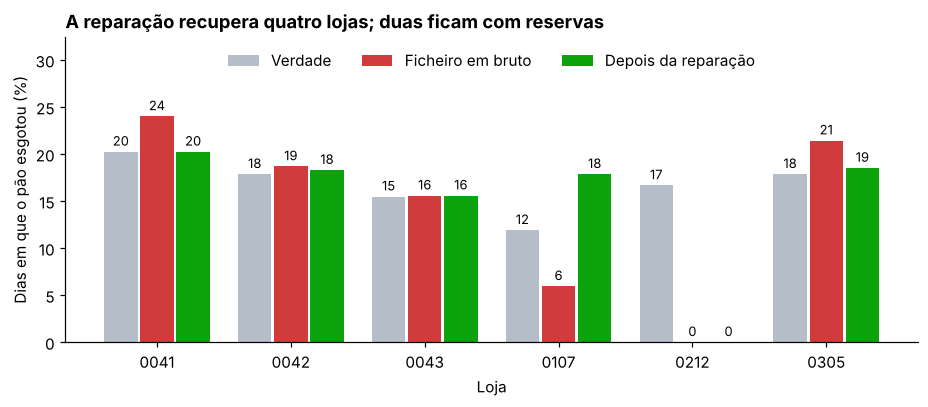

In [10]:
def taxa_esgotou(tabela, tolerancia=None):
    t = tabela.dropna(subset=["vendidos"])
    limite = t["produzidos"] - (np.where(t["vendidos_aproximado"], 6, 0) if tolerancia else 0)
    return (t["vendidos"] >= limite).groupby(t["loja_id"]).mean() * 100


comparacao = pd.DataFrame({"Verdade": taxa_esgotou(vendas),
                           "Ficheiro em bruto": taxa_esgotou(bruto),
                           "Depois da reparação": taxa_esgotou(limpo, tolerancia=True)})
print(comparacao.round(1), "\n")

seis = comparacao.loc[ids]
x = np.arange(6)
fig, ax = plt.subplots(figsize=(10, 3.6))
for k, (coluna, cor) in enumerate(zip(seis.columns, [CINZA, MAU, BOM])):
    barras = ax.bar(x + (k - 1) * 0.27, seis[coluna].fillna(0), 0.25, color=cor, label=coluna)
    ax.bar_label(barras, fmt="%.0f", padding=2, fontsize=8.5)
ax.set_xticks(x, ids)
ax.set_xlabel("Loja")
ax.set_ylabel("Dias em que o pão esgotou (%)")
ax.set_title("A reparação recupera quatro lojas; duas ficam com reservas")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.0))
ax.set_ylim(0, seis.max().max() * 1.35)
plt.show()

Lê a figura loja a loja:

- **`0041`:** no ficheiro em bruto a loja estava partida em duas (`0041` e `41`, que aparece na tabela impressa como uma sétima loja). Depois da normalização, o valor coincide com a verdade.
- **`0042`:** os duplicados distorciam ligeiramente a taxa; a reparação aproxima-a da verdade.
- **`0043`:** falta uma semana, e a taxa fica próxima da verdadeira. Os valores em falta custaram precisão, mas não introduziram um erro sistemático, porque uma avaria não escolhe os dias.
- **`0107`:** em bruto, a loja parecia deixar de esgotar o pão a partir de abril (6%). A conversão recupera a escala, mas não o rótulo: a regra «vendeu tudo» precisa do valor exato, e o arredondamento a dúzias apagou-o. Com uma tolerância de 6 pães obtém-se 18%; sem tolerância, os mesmos 6% do ficheiro em bruto. A verdade (12%) fica entre os dois, e só um reenvio dos dados em unidades a recupera.
- **`0212`:** continua em **zero**, antes e depois. A reparação não pode recuperar dias que nunca foram registados. Este é o único erro que sobreviveu à limpeza, e é o maior.
- **`0305`:** os três valores dez vezes acima da produção contavam como dias em que o pão esgotou. Passaram a valores em falta e a taxa aproxima-se da verdadeira.

> **Limpar não corrige o enviesamento.** Uma tabela pode passar em todas as verificações e continuar a responder mal à pergunta. A cobertura (quem e o que está representado) verifica-se à parte, e a resposta honesta é muitas vezes «com estes dados, sobre isto não se pode concluir».

## Resumo do módulo: quatro passos, um método

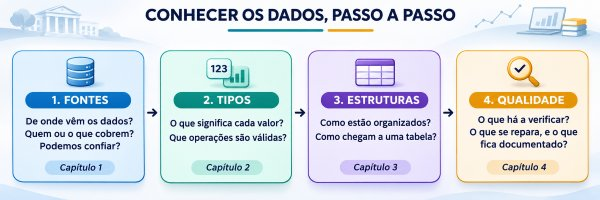

No CRISP-DM (módulo 1, capítulo 4), estas quatro perguntas são o trabalho das fases de **compreensão dos dados** e de **preparação dos dados**, as que ocupam a maior parte do tempo de um projeto.

## Exercícios

### `Exercício 1` – Que família de problema?

Classifica cada situação (consistência, completude, validade, duplicação ou enviesamento):

1. Uma tabela de clientes tem o mesmo cliente três vezes, com o apelido escrito de formas ligeiramente diferentes.
2. Num inquérito sobre hábitos de leitura feito à porta de uma biblioteca, 95% dizem ler todas as semanas.
3. A coluna `idade` tem valores de 212 e de −3.
4. Metade das lojas regista o peso em quilogramas e a outra metade em gramas.
5. Um sensor de temperatura deixou de comunicar entre as 2h00 e as 6h00.
6. Um modelo de reconhecimento de voz foi treinado quase só com gravações de locutores profissionais.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Duplicação (com um problema de consistência na escrita dos nomes).
2. Enviesamento: quem está à porta de uma biblioteca não representa a população.
3. Validade.
4. Consistência.
5. Completude. Se as falhas acontecerem sempre de madrugada, passa também a ser enviesamento: a temperatura média fica sobrestimada.
6. Enviesamento.

</details>

### `Exercício 2` – Auditar outra tabela

A célula seguinte estraga a tabela `meteo`. Encontra os quatro problemas, sem olhares para o código que os criou.

In [11]:
meteo_bruto = meteo.copy()
meteo_bruto.loc[10:16, "chuva_mm"] = np.nan
meteo_bruto.loc[30, "chuva_mm"] = -4.0
meteo_bruto.loc[50:, "chuva_mm"] = (meteo_bruto.loc[50:, "chuva_mm"] / 10).round(2)
meteo_bruto = pd.concat([meteo_bruto, meteo_bruto.iloc[[20, 21]]], ignore_index=True)
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
print("Linhas:", len(meteo_bruto), "| dias distintos:", meteo_bruto["data"].nunique())
print("Duplicadas:", int(meteo_bruto.duplicated().sum()))
print("Em falta:", int(meteo_bruto["chuva_mm"].isna().sum()))
print("Negativas:", int((meteo_bruto["chuva_mm"] < 0).sum()))
print(meteo_bruto.groupby(meteo_bruto.index // 28)["chuva_mm"].agg(["mean", "max"]).round(2))
```

Há duas linhas duplicadas, sete dias seguidos em falta, um valor negativo e, a partir da linha 50, valores cerca de dez vezes mais pequenos (provavelmente centímetros em vez de milímetros). O último é o mais difícil de ver: nenhum valor é impossível, só a escala mudou.

</details>

### `Exercício 3` – Preencher ou não preencher?

Um colega propõe preencher a semana em falta da loja `0043` com a média dessa loja. Que efeito teria na taxa de dias em que o pão esgotou? E na variabilidade das vendas? Que alternativa proporias?

<details>
<summary><b>Ver uma solução possível</b></summary>

A média da loja é inferior à produção, por isso os sete dias preenchidos contariam todos como «não esgotou», incluindo o sábado, e a taxa desceria. A variabilidade também desceria, porque se acrescentam sete valores iguais.

Alternativas: deixar em falta (a que escolhemos); preencher cada dia com a mediana do mesmo dia da semana, assinalando os valores preenchidos numa coluna própria; ou pedir à loja os registos em papel dessa semana.

</details>

### `Exercício 4` – O registo de alterações

Escreve, em três ou quatro frases, a nota que acompanharia a tabela `limpo` quando a entregasses a um colega. O que é que ele precisa de saber antes de a usar?

<details>
<summary><b>Ver uma solução possível</b></summary>

«Tabela de vendas diárias por loja, de 2 de março a 24 de maio de 2026, reparada a partir do ficheiro em bruto (que se mantém inalterado). As vendas da loja 0107 a partir de 13 de abril foram convertidas de dúzias e têm um erro de até 6 pães (coluna `vendidos_aproximado`); a conversão aguarda confirmação da loja. Há valores em falta na loja 0043 (semana de 6 de abril, avaria) e em cinco dias das lojas 0042 e 0305 (valores inválidos, à espera de esclarecimento). A loja 0212 não tem registos de fim de semana: não uses esta tabela para tirar conclusões sobre os sábados e os domingos dessa loja.»

</details>

## Verifica o que aprendeste

- [ ] Sei enumerar as cinco famílias de problemas de qualidade e dar um exemplo de cada.
- [ ] Sei fazer uma auditoria a uma tabela: primeiro olhar, consistência, completude, validade e duplicação.
- [ ] Sei porque o enviesamento não se deteta verificando o esquema.
- [ ] Sei distinguir quando normalizar, quando investigar e quando documentar.
- [ ] Sei porque não se alteram os dados em bruto e porque se regista cada decisão.
- [ ] Sei explicar porque limpar os dados não corrige um enviesamento.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Data_quality
- https://en.wikipedia.org/wiki/Data_cleansing
- https://pandas.pydata.org/docs/user_guide/duplicates.html
- https://pandas.pydata.org/docs/user_guide/missing_data.html